# Unit 2: a reproducible attrition classification prototype

**Defined analytical problem (LO1.3):** classify recorded attrition using ten numerical account activity features. Positive class = attrited customer. **BR4:** compare a useful classifier with a majority baseline, report detection/workload trade-offs and explain the limits of deployment.

This is retrospective snapshot classification. There is no timestamped prediction point or future outcome window. Unit 1 analysed the full dataset; the test split is an internal check within this known dataset, not an independent external validation.

In [1]:
# Resolve paths when launched from either the root or notebook directory.
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from src.data import extract_transform_load, OUTPUT, FEATURES
from src.statistics import wilson_interval, segment_summary, test_hypotheses
plt.rcParams.update({'figure.figsize': (9, 5), 'axes.spines.top': False, 'axes.spines.right': False})
df, quality = extract_transform_load()
print(f'{len(df):,} customer snapshots; {df.Churn.sum():,} attrited ({df.Churn.mean():.2%}).')

10,127 customer snapshots; 1,627 attrited (16.07%).


## Method selection and exclusions (LO2.2)

Logistic regression offers a scaled, regularised, approximately linear benchmark. A random forest can capture nonlinear activity interactions (for example balance together with transaction count), but is less transparent and can overfit. Compare them with three-fold stratified training cross-validation and select by mean average precision (AP). No broad hyperparameter search is attempted: depth 10, minimum leaf size 5 and 150 trees limit complexity and computation.

A majority classifier supplies the baseline. Accuracy alone is unsuitable: a model predicting everyone retained is already about 84% accurate. AP assesses ranking of the minority class; precision reports how much outreach would be wasted and recall reports how many recorded attrition cases are detected. ROC AUC is supplementary. F2 weights recall more heavily, but has no direct monetary interpretation.

Identifiers, original target text, derived target, stored classifier outputs, redundant open-to-buy, demographics, card category and tenure are excluded from features. Excluding demographics does not establish fairness; behaviour can contain proxies. Closure timing remains a possible source of outcome leakage even after stored predictions are removed.

In [2]:
# Audit disjoint partitions before training; row numbers are not model features.
from src.modelling import split_data, run_modelling
train, validation, test = split_data(df)
assert set(train.index).isdisjoint(validation.index)
assert set(train.index).isdisjoint(test.index)
assert set(validation.index).isdisjoint(test.index)
display(pd.DataFrame({'split':['train','validation','test'],'customers':[len(train),len(validation),len(test)],'attrition_rate':[train.Churn.mean(),validation.Churn.mean(),test.Churn.mean()]}))
print('Model features:', FEATURES)

,split,customers,attrition_rate
0,train,6076,0.160632
1,validation,2025,0.160494
2,test,2026,0.160908


Model features: ['Total_Relationship_Count', 'Months_Inactive_12_mon', 'Contacts_Count_12_mon', 'Credit_Limit', 'Total_Revolving_Bal', 'Total_Amt_Chng_Q4_Q1', 'Total_Trans_Amt', 'Total_Trans_Ct', 'Total_Ct_Chng_Q4_Q1', 'Avg_Utilization_Ratio']


## Fitting and decision protocol

1. Make a reproducible stratified 60/20/20 split (seed 42).
2. Fit imputation/scaling **inside each training cross-validation fold** using scikit-learn pipelines. All supplied numerical features are currently complete; a median imputer defines future handling without inventing demographic attributes.
3. Select the model with greatest mean training CV AP, then fit it on the training split.
4. On validation only, choose among thresholds 0.05–0.95 (step 0.025): maximise recall subject to precision ≥60%, then prefer precision and the higher threshold on ties. This floor is an illustrative business constraint because outreach costs are not supplied. If infeasible, the code records that and selects from all candidates.
5. Lock those decisions and evaluate the test split. The model is not refitted on validation/test.
6. Examine validation permutation importance and a validation sensitivity run excluding contacts; these are diagnostics and do not tune test decisions.

Class weighting changes decision scores. Those scores are **not calibrated future churn probabilities**. A random split checks generalisation to similar rows only. Temporal/external validation and calibration assessment would be required for a real forecasting service.

In [3]:
# Execute the full pipeline from raw data; save metrics, splits and diagnostics.
result, comparison, importance, predictions = run_modelling(df)
display(comparison)
print('Selected model:', result['selected_model'])
print('Validation precision floor met:',result['validation_precision_floor_met'])
display(pd.DataFrame([result['test'],result['dummy_test']],index=['Selected test model','Majority baseline']))
print('Conditional bootstrap 95% interval for test AP:',result['test_ap_bootstrap_95'])

,model,cv_ap_mean,cv_ap_sd,cv_roc_mean
1,Random forest,0.913926,0.001251,0.983762
0,Logistic regression,0.716662,0.018273,0.919855


Selected model: Random forest
Validation precision floor met: True


,threshold,accuracy,balanced_accuracy,precision,recall,f2,average_precision,roc_auc,tn,fp,fn,tp
Selected test model,0.25,0.896841,0.924894,0.614035,0.966258,0.866813,0.921873,0.983371,1502,198,11,315
Majority baseline,0.50,0.839092,0.500000,0.000000,0.000000,0.000000,0.160908,0.500000,1700,0,326,0


Conditional bootstrap 95% interval for test AP: [0.8990141314672132, 0.942164747911494]


## Uncertainty and test interpretation (LO3.2)

The AP interval uses 300 bootstrap resamples of test customers with a fixed fitted model. It describes uncertainty conditional on this sample and fitted model. It does not capture retraining variability, prior exploratory selection, bank differences, time drift or the missing prediction window. Cross-validation standard deviation is fold variation, not a confidence interval.

An AP increase over the majority baseline demonstrates better internal ranking of observed statuses. It does not prove that contacted customers can be retained or that a campaign will be profitable.

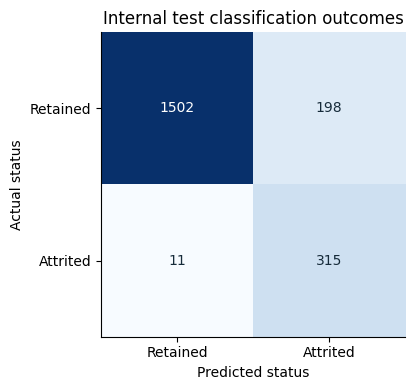

Detected 315 of 326 attrited customers; 198 false alarms; 11 missed cases.


In [4]:
# Plot explicit error counts rather than treating accuracy as the sole success criterion.
r = result['test']
matrix = np.array([[r['tn'],r['fp']],[r['fn'],r['tp']]])
fig, ax = plt.subplots(figsize=(6,4))
ax.imshow(matrix,cmap='Blues')
for (i,j), value in np.ndenumerate(matrix):
 ax.text(j,i,str(value),ha='center',va='center',color='white' if value>matrix.max()/2 else '#162B3A')
ax.set(xticks=[0,1],yticks=[0,1],xticklabels=['Retained','Attrited'],yticklabels=['Retained','Attrited'],xlabel='Predicted status',ylabel='Actual status',title='Internal test classification outcomes')
fig.tight_layout()
fig.savefig(OUTPUT/'confusion_matrix.png',dpi=160)
plt.show()
print(f"Detected {r['tp']} of {r['tp']+r['fn']} attrited customers; {r['fp']} false alarms; {r['fn']} missed cases.")

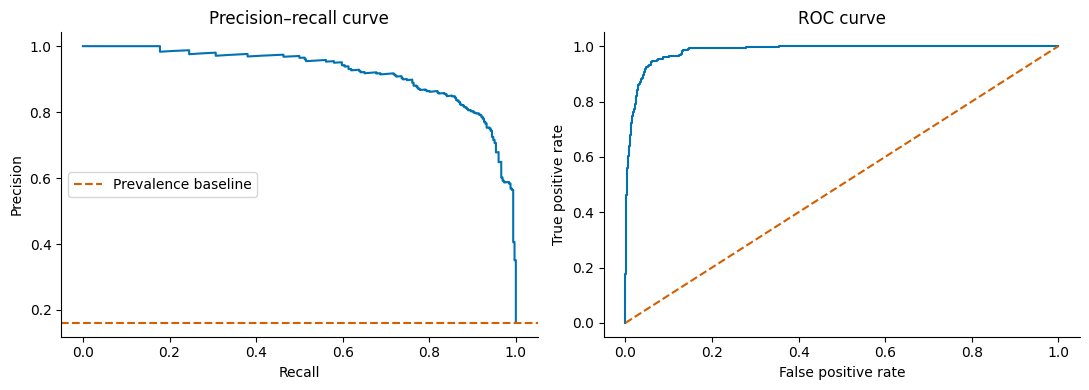

In [5]:
# Inspect test ranking after the model and threshold have already been locked.
from sklearn.metrics import precision_recall_curve, roc_curve
p, recall, _ = precision_recall_curve(predictions.actual_churn,predictions.score)
fpr,tpr,_ = roc_curve(predictions.actual_churn,predictions.score)
fig, axes = plt.subplots(1,2,figsize=(11,4))
axes[0].plot(recall,p,color='#0072B2')
axes[0].axhline(predictions.actual_churn.mean(),ls='--',color='#D55E00',label='Prevalence baseline')
axes[0].set(xlabel='Recall',ylabel='Precision',title='Precision–recall curve'); axes[0].legend()
axes[1].plot(fpr,tpr,color='#0072B2')
axes[1].plot([0,1],[0,1],ls='--',color='#D55E00')
axes[1].set(xlabel='False positive rate',ylabel='True positive rate',title='ROC curve')
fig.tight_layout()
fig.savefig(OUTPUT/'model_curves.png',dpi=160)
plt.show()

,feature,ap_decrease,sd
7,Total_Trans_Ct,0.414782,0.031834
6,Total_Trans_Amt,0.217449,0.015264
0,Total_Relationship_Count,0.064978,0.006366
4,Total_Revolving_Bal,0.038624,0.009786
8,Total_Ct_Chng_Q4_Q1,0.035839,0.008593
5,Total_Amt_Chng_Q4_Q1,0.022641,0.003643
1,Months_Inactive_12_mon,0.017637,0.004891
3,Credit_Limit,0.012982,0.001218
2,Contacts_Count_12_mon,0.004503,0.001655
9,Avg_Utilization_Ratio,-0.001947,0.003211


Validation AP with contacts: 0.9256457047116164
Validation AP without contacts: 0.9257593985267734


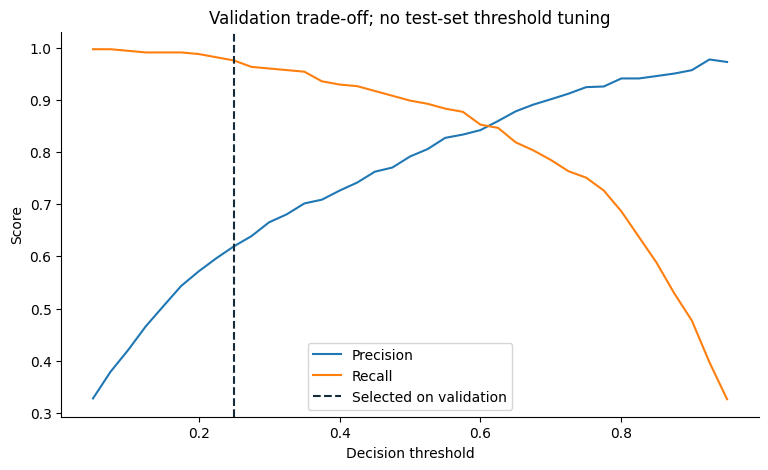

In [6]:
# Validation-only reliance and timing sensitivity; neither is a causal explanation.
display(importance)
print('Validation AP with contacts:',result['validation_ap_with_contacts'])
print('Validation AP without contacts:',result['validation_ap_without_contacts'])
thresholds = pd.read_csv(OUTPUT/'validation_thresholds.csv')
fig, ax = plt.subplots()
ax.plot(thresholds.threshold,thresholds.precision,label='Precision')
ax.plot(thresholds.threshold,thresholds.recall,label='Recall')
ax.axvline(result['test']['threshold'],ls='--',color='#162B3A',label='Selected on validation')
ax.set(xlabel='Decision threshold',ylabel='Score',title='Validation trade-off; no test-set threshold tuning')
ax.legend(); plt.show()

## Recommendations and adaptation (LO3.2, LO4.1, LO4.2)

Use the dashboard for **historical exploration**, not customer eligibility decisions. Activity and portfolio structure warrant further investigation. A production study needs dated features measured before a defined attrition horizon, an external or temporal test, calibration, subgroup error analysis, agreed outreach costs and intervention evidence. Removing contact count barely changes validation AP, so its ambiguous timing is avoidable in a future study; that alone does not solve timing uncertainty in all other activity fields.

This implementation moved from sequential notebook transformations to validated reusable functions and train-only pipelines. Automated guardrails catch duplicate IDs, unexpected labels and invalid values before reports are produced. Hexbin/density views handle overlapping observations more clearly. A separate lean Unit 2 dependency file avoids the legacy profiling helper's installation constraints. These are documented engineering changes, **not a claim about Asim's personal learning**.

Before submission, Asim should review the actual results, run the project himself and complete the personal learning/AI reflection prompts in `docs/LEARNING_REFLECTION.md`. The assistance log records what was actually done and must not be presented as unaided work. Streamlit execution, interaction tests and deployment status are documented in the README.